# Caltech101 image classification (revised)

Fixes versus the original notebook:
- Accuracy is now reported on the **test** split (the old run evaluated `train_loader`).
- **Separate transforms**: random augmentation for train only, deterministic resize and center crop for test.
- **Stratified, seeded split** so every class appears in both splits and the split is reproducible.
- Normalization stats are **computed from the training images** (incrementally, no giant tensor).
- Lower learning rate (AdamW + cosine schedule), batch size 32, deeper CNN, dropout only in the classifier head.
- Optional **pretrained ResNet18** (`USE_PRETRAINED = True`), per-epoch accuracy, best-model checkpoint, and curves.

In [1]:
import random
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset

import torchvision
from torchvision.transforms import v2

In [8]:
# ---------------- Config ----------------
SEED = 42
USE_PRETRAINED = False      # True -> ImageNet-pretrained ResNet18 (much higher accuracy)
BATCH_SIZE = 32
EPOCHS = 20
LR = 3e-4 if USE_PRETRAINED else 1e-3
WEIGHT_DECAY = 1e-4
TRAIN_FRAC = 0.8
NUM_WORKERS = 0
IMG_SIZE = 224
CKPT_PATH = 'best_model.pt'

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

device = (torch.accelerator.current_accelerator().type
          if torch.accelerator.is_available() else 'cpu')
print('device:', device)

device: cuda


## Data: load once without a transform, then split

In [ ]:
# transform=None -> samples are PIL images, so each split can get its own transform later.
base_data = torchvision.datasets.Caltech101(root='caltech101', download=True, transform=None)

labels = np.array(base_data.y)
num_classes = len(base_data.categories)
print('samples:', len(base_data), '| classes:', num_classes)

100.0%


samples: 8677 | classes: 101


In [4]:
# Stratified split: take TRAIN_FRAC of each class (at least 1 sample in each split).
rng = np.random.default_rng(SEED)
train_idx, test_idx = [], []
for c in range(num_classes):
    idx = np.where(labels == c)[0]
    rng.shuffle(idx)
    n_train = min(max(1, int(round(TRAIN_FRAC * len(idx)))), len(idx) - 1)
    train_idx.extend(idx[:n_train].tolist())
    test_idx.extend(idx[n_train:].tolist())

print('train:', len(train_idx), '| test:', len(test_idx))
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(base_data)

train: 6941 | test: 1736


In [5]:
class TransformedSubset(Dataset):
    """A subset of `base` that applies its own transform (so train and test can differ)."""
    def __init__(self, base, indices, transform):
        self.base, self.indices, self.transform = base, indices, transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        img, label = self.base[self.indices[i]]
        return self.transform(img), label

## Normalization statistics (from the training images only)

Computed incrementally from per-channel sums, using a small resize for speed (approximate is fine for normalization).
When using the pretrained ResNet, the ImageNet statistics are used instead.

In [7]:
def compute_mean_std(base, indices, size=64, batch_size=128):
    tfm = v2.Compose([
        v2.RGB(),
        v2.Resize((size, size), antialias=True),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
    ])
    loader = DataLoader(TransformedSubset(base, indices, tfm),
                        batch_size=batch_size, num_workers=0)
    total = torch.zeros(3, dtype=torch.float64)
    total_sq = torch.zeros(3, dtype=torch.float64)
    n_pixels = 0
    for x, _ in loader:
        x = x.double()
        total += x.sum(dim=(0, 2, 3))
        total_sq += (x ** 2).sum(dim=(0, 2, 3))
        n_pixels += x.shape[0] * x.shape[2] * x.shape[3]
    mean = total / n_pixels
    std = (total_sq / n_pixels - mean ** 2).sqrt()
    return mean.float().tolist(), std.float().tolist()

if USE_PRETRAINED:
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
else:
    MEAN, STD = compute_mean_std(base_data, train_idx)
print('mean:', MEAN)
print('std: ', STD)

mean: [0.5452225208282471, 0.5272243618965149, 0.5001878142356873]
std:  [0.30344846844673157, 0.2972407639026642, 0.31034329533576965]


In [9]:
train_tfm = v2.Compose([
    v2.RGB(),                                            # handles grayscale and RGBA
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), antialias=True),
    v2.RandomHorizontalFlip(),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

test_tfm = v2.Compose([                                   # deterministic
    v2.RGB(),
    v2.Resize(256, antialias=True),
    v2.CenterCrop(IMG_SIZE),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])

train_dataset = TransformedSubset(base_data, train_idx, train_tfm)
test_dataset = TransformedSubset(base_data, test_idx, test_tfm)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(device == 'cuda'),
                          drop_last=True)   # avoids a size-1 final batch for BatchNorm
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=(device == 'cuda'))

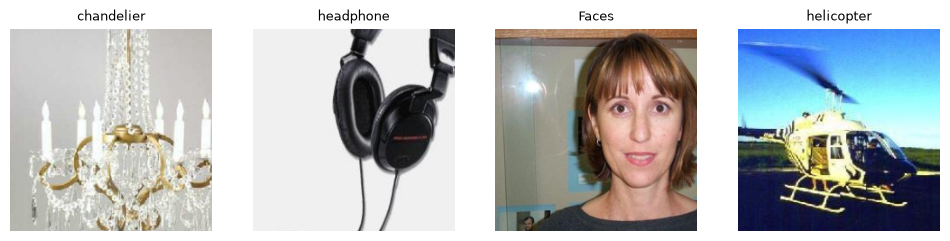

In [10]:
# Visualize a few training samples with class names
mean_t = torch.tensor(MEAN).view(-1, 1, 1)
std_t = torch.tensor(STD).view(-1, 1, 1)

def unnormalize(t):
    return torch.clamp(t * std_t + mean_t, 0, 1)

images, ys = next(iter(train_loader))
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, img, y in zip(axes, images[:4], ys[:4]):
    ax.imshow(unnormalize(img).permute(1, 2, 0).numpy())
    ax.set_title(base_data.categories[y.item()], fontsize=9)
    ax.axis('off')
plt.show()

## Model

In [ ]:
def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

class Model(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32),     # 224 -> 112
            conv_block(32, 64),    # -> 56
            conv_block(64, 128),   # -> 28
            conv_block(128, 256),  # -> 14
            conv_block(256, 256),  # -> 7
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(      # dropout only in the head
            nn.Flatten(),
            nn.Linear(256, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def build_model():
    if USE_PRETRAINED:
        m = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.DEFAULT)
        m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, num_classes))
        return m
    return Model(num_classes)

model = build_model().to(device)
print(f'parameters: {sum(p.numel() for p in model.parameters()):,}')

parameters: 2,446,149


In [12]:
try:
    from torchinfo import summary
    summary(model, input_size=(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE))
except ImportError:
    print('torchinfo not installed (pip install torchinfo) - skipping summary')

## Training

In [13]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader))

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                scheduler.step()
            total_loss += loss.item() * targets.size(0)
            correct += (outputs.argmax(1) == targets).sum().item()
            n += targets.size(0)
    return total_loss / n, correct / n

In [14]:
history = defaultdict(list)
best_acc = 0.0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    te_loss, te_acc = run_epoch(test_loader, train=False)

    for k, v in zip(['train_loss', 'train_acc', 'test_loss', 'test_acc'],
                    [tr_loss, tr_acc, te_loss, te_acc]):
        history[k].append(v)

    if te_acc > best_acc:
        best_acc = te_acc
        torch.save(model.state_dict(), CKPT_PATH)

    print(f'Epoch {epoch:2d}/{EPOCHS} | '
          f'train loss {tr_loss:.3f} acc {tr_acc:.1%} | '
          f'test loss {te_loss:.3f} acc {te_acc:.1%}')

print(f'\nBest test accuracy: {best_acc:.2%}')

Epoch  1/20 | train loss 4.013 acc 21.9% | test loss 3.605 acc 28.2%
Epoch  2/20 | train loss 3.523 acc 29.8% | test loss 3.358 acc 32.6%
Epoch  3/20 | train loss 3.308 acc 33.8% | test loss 3.248 acc 33.9%
Epoch  4/20 | train loss 3.063 acc 38.5% | test loss 3.187 acc 30.6%
Epoch  5/20 | train loss 2.878 acc 42.3% | test loss 3.269 acc 31.2%
Epoch  6/20 | train loss 2.698 acc 46.2% | test loss 2.771 acc 45.7%
Epoch  7/20 | train loss 2.525 acc 50.5% | test loss 2.549 acc 50.9%
Epoch  8/20 | train loss 2.409 acc 53.2% | test loss 2.522 acc 50.9%
Epoch  9/20 | train loss 2.309 acc 56.4% | test loss 2.458 acc 53.3%
Epoch 10/20 | train loss 2.187 acc 60.4% | test loss 2.160 acc 60.9%
Epoch 11/20 | train loss 2.118 acc 61.6% | test loss 2.204 acc 60.3%
Epoch 12/20 | train loss 1.999 acc 65.2% | test loss 2.037 acc 64.7%
Epoch 13/20 | train loss 1.905 acc 68.3% | test loss 1.931 acc 66.3%
Epoch 14/20 | train loss 1.821 acc 71.7% | test loss 1.894 acc 68.0%
Epoch 15/20 | train loss 1.761 acc

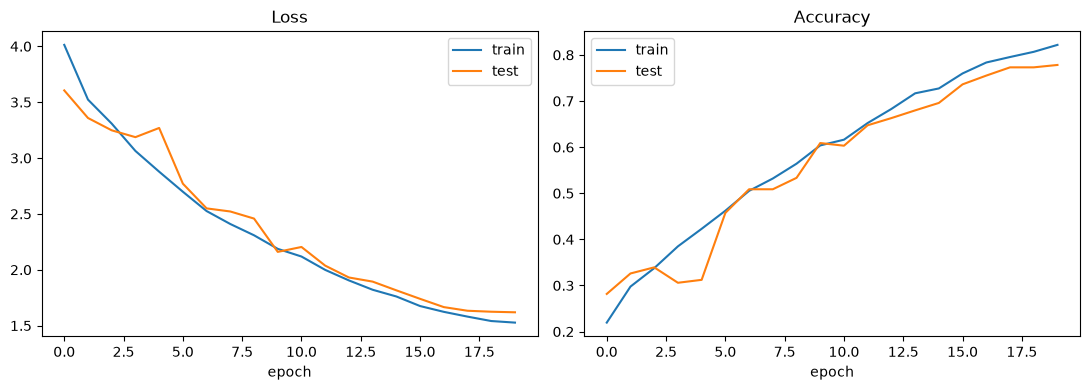

In [15]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.plot(history['train_loss'], label='train'); a1.plot(history['test_loss'], label='test')
a1.set_title('Loss'); a1.set_xlabel('epoch'); a1.legend()
a2.plot(history['train_acc'], label='train'); a2.plot(history['test_acc'], label='test')
a2.set_title('Accuracy'); a2.set_xlabel('epoch'); a2.legend()
plt.tight_layout(); plt.show()

## Final evaluation (best checkpoint, test split)

In [16]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
test_loss, test_acc = run_epoch(test_loader, train=False)
print(f'Test accuracy: {test_acc * 100:.2f}%  (loss {test_loss:.3f})')

Test accuracy: 77.82%  (loss 1.619)


In [17]:
# Per-class accuracy: Caltech101 is imbalanced, so overall accuracy can hide weak classes.
model.eval()
per_correct = np.zeros(num_classes)
per_total = np.zeros(num_classes)
with torch.no_grad():
    for inputs, targets in test_loader:
        preds = model(inputs.to(device)).argmax(1).cpu()
        for t, p in zip(targets.numpy(), preds.numpy()):
            per_total[t] += 1
            per_correct[t] += int(t == p)

per_acc = per_correct / np.maximum(per_total, 1)
print(f'Mean per-class accuracy: {per_acc.mean():.2%}')
print('Weakest 5 classes:')
for c in np.argsort(per_acc)[:5]:
    print(f'  {base_data.categories[c]:<20} {per_acc[c]:.0%} ({int(per_total[c])} test imgs)')

Mean per-class accuracy: 67.47%
Weakest 5 classes:
  anchor               0% (8 test imgs)
  water_lilly          0% (7 test imgs)
  okapi                12% (8 test imgs)
  crab                 13% (15 test imgs)
  gerenuk              14% (7 test imgs)
